In [6]:
from google.colab import drive
drive.mount('/content/drive')
import numpy as np
import pandas as pd


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:

train_X = pd.read_csv('/content/drive/MyDrive/2026Projects/nameThatLLM/dataset/train.csv')
test_X = pd.read_csv('/content/drive/MyDrive/2026Projects/nameThatLLM/dataset/test.csv')

In [8]:
train_X

,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash
...,...,...,...,...
2694,ff4344ceda23,p075,"Across centuries of silence and shadow, an inv...",gemini-3.8-flash
2695,ff507658ba82,p092,Though both instruments breathe the exact same...,gemini-3.7-flash
2696,ff50c252810c,p113,A single photon leaves the star as neither wav...,claude-opus-4-8
2697,ffcf6321f7e9,p073,Data science communities matter because they t...,glm-5.3


### Exploratory Data Analysis (EDA)
We will analyze the target classes, prompt distribution, and text length statistics.

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Target Class Distribution
print("=== Model Class Distribution ===")
model_counts = train_X['model'].value_counts()
print(model_counts)

# 2. Unique Prompts count
print("\n=== Unique Prompts ===")
print(f"Number of unique prompts: {train_X['prompt_id'].nunique()}")

# 3. Calculate text lengths
train_X['char_len'] = train_X['text'].astype(str).apply(len)
train_X['word_len'] = train_X['text'].astype(str).apply(lambda x: len(x.split()))

print("\n=== Text Length Statistics (Characters) ===")
print(train_X['char_len'].describe())

print("\n=== Text Length Statistics (Words) ===")
print(train_X['word_len'].describe())

=== Model Class Distribution ===
model
qwen3.8-max               150
claude-sonnet-5           150
gemini-3.6-flash          150
gpt-5.6-terra             150
glm-5.3-flash             150
gemini-3.1-pro-preview    150
gemini-3.8-flash          150
claude-opus-4-6           150
gpt-5.6-luna              150
claude-opus-4-8           150
gemini-3.7-flash          150
claude-opus-5             150
kimi-k3                   150
gpt-5.5                   150
glm-5.3                   150
gpt-6-astra               150
gpt-5.6-sol               150
claude-fable-5            149
Name: count, dtype: int64

=== Unique Prompts ===
Number of unique prompts: 150

=== Text Length Statistics (Characters) ===
count    2699.000000
mean      755.289366
std       377.371075
min       230.000000
25%       429.000000
50%       670.000000
75%      1027.000000
max      1900.000000
Name: char_len, dtype: float64

=== Text Length Statistics (Words) ===
count    2699.000000
mean      114.659504
std        58.2

/tmp/ipykernel_917/1133294725.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_X, y='model', order=model_counts.index, ax=axes[0], palette='viridis')


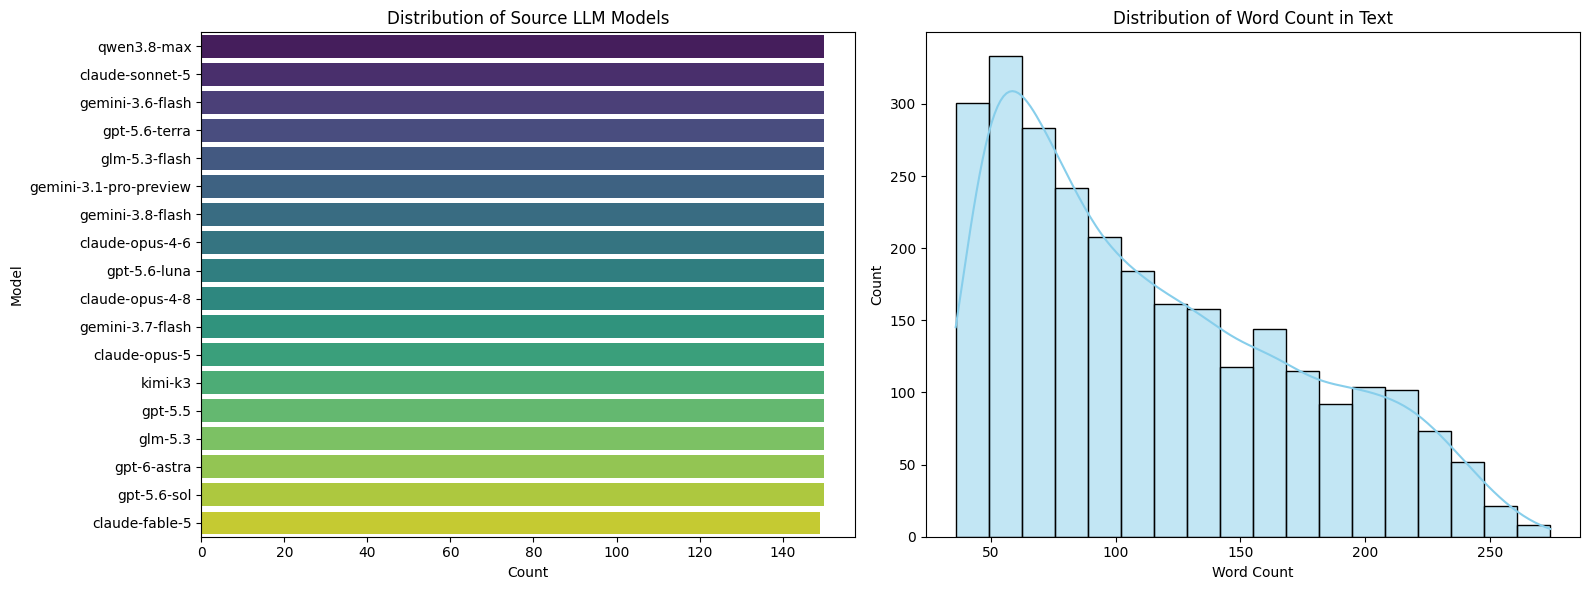

In [12]:
# Visualize the distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.countplot(data=train_X, y='model', order=model_counts.index, ax=axes[0], palette='viridis')
axes[0].set_title('Distribution of Source LLM Models')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('Model')

sns.histplot(data=train_X, x='word_len', kde=True, ax=axes[1], color='skyblue')
axes[1].set_title('Distribution of Word Count in Text')
axes[1].set_xlabel('Word Count')

plt.tight_layout()
plt.show()

### Baseline Model: TF-IDF + Logistic Regression
We will use a combined Word + Char TF-IDF representation and evaluate it using Stratified 5-Fold Cross Validation.

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
import numpy as np

# 1. Encode Target Labels
le = LabelEncoder()
y = le.fit_transform(train_X['model'])
X_text = train_X['text']

# 2. Build Feature Extractor
# Word n-grams and character n-grams to capture stylistic patterns
word_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='word',
    token_pattern=r'\w{1,}',
    ngram_range=(1, 2),
    max_features=15000
)

char_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='char',
    ngram_range=(2, 5),
    max_features=30000
)

vectorizer = FeatureUnion([
    ('word', word_vectorizer),
    ('char', char_vectorizer)
])

print('Extracting features...')
X_features = vectorizer.fit_transform(X_text)
print(f'Feature matrix shape: {X_features.shape}')

Extracting features...
Feature matrix shape: (2699, 45000)


In [14]:
# 3. Evaluate using Stratified 5-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf = LogisticRegression(C=2.0, max_iter=1000, solver='saga', multi_class='multinomial', n_jobs=-1)

print('Running cross-validation...')
scores = cross_val_score(clf, X_features, y, cv=cv, scoring='accuracy', n_jobs=-1)

print(f'Mean CV Accuracy: {np.mean(scores):.4f} (+/- {np.std(scores):.4f})')

Running cross-validation...
Mean CV Accuracy: 0.1167 (+/- 0.0061)


### Baseline Model: TF-IDF + Logistic Regression
We will use a combined Word + Char TF-IDF representation and evaluate it using Stratified 5-Fold Cross Validation.

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
import numpy as np

# 1. Encode Target Labels
le = LabelEncoder()
y = le.fit_transform(train_X['model'])
X_text = train_X['text']

# 2. Build Feature Extractor
# Word n-grams and character n-grams to capture stylistic patterns
word_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='word',
    token_pattern=r'\w{1,}',
    ngram_range=(1, 2),
    max_features=15000
)

char_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='char',
    ngram_range=(2, 5),
    max_features=30000
)

vectorizer = FeatureUnion([
    ('word', word_vectorizer),
    ('char', char_vectorizer)
])

print("Extracting features...")
X_features = vectorizer.fit_transform(X_text)
print(f"Feature matrix shape: {X_features.shape}")

Extracting features...
Feature matrix shape: (2699, 45000)


In [16]:
# 3. Evaluate using Stratified 5-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf = LogisticRegression(C=2.0, max_iter=1000, solver='saga', multi_class='multinomial', n_jobs=-1)

print("Running cross-validation...")
scores = cross_val_score(clf, X_features, y, cv=cv, scoring='accuracy', n_jobs=-1)

print(f"Mean CV Accuracy: {np.mean(scores):.4f} (+/- {np.std(scores):.4f})")

Running cross-validation...
Mean CV Accuracy: 0.1178 (+/- 0.0076)


### Transformer Model: DeBERTa-v3 Fine-tuning
We will use `transformers` and `datasets` to fine-tune a pre-trained `DeBERTa-v3-small` model. First, we install the required packages.

In [17]:
!pip install -q transformers[torch] datasets accelerate evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 1.8 MB/s eta 0:00:00


In [18]:
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
import numpy as np
import evaluate

# Check for GPU availability
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {device}')

# Use 'microsoft/deberta-v3-small' as it is highly efficient and powerful for text classification
MODEL_NAME = 'microsoft/deberta-v3-small'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

# Prepare training and validation split (e.g., 85% train, 15% validation)
df_train = train_X.sample(frac=1, random_state=42).reset_index(drop=True)
df_train['label'] = le.transform(df_train['model'])

train_split = df_train.sample(frac=0.85, random_state=42)
val_split = df_train.drop(train_split.index)

train_dataset = Dataset.from_pandas(train_split[['text', 'label']])
val_dataset = Dataset.from_pandas(val_split[['text', 'label']])

def tokenize_function(examples):
    return tokenizer(examples['text'], truncation=True, max_length=512)

tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_val = val_dataset.map(tokenize_function, batched=True)

# Load accuracy metric
metric = evaluate.load('accuracy')
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)

Using device: cpu


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

Map:   0%|          | 0/2294 [00:00<?, ? examples/s]

Map:   0%|          | 0/405 [00:00<?, ? examples/s]

In [19]:
# Load the pre-trained Sequence Classification model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(le.classes_)
)

training_args = TrainingArguments(
    output_dir='./results',
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    evaluation_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='accuracy',
    fp16=True if device == 'cuda' else False,
    report_to='none'
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics
)

# Run the fine-tuning process
trainer.train()

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  286MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
classifie

TypeError: TrainingArguments.__init__() got an unexpected keyword argument 'evaluation_strategy'

### Transformer Model: DeBERTa-v3 Fine-tuning
We will use `transformers` and `datasets` to fine-tune a pre-trained `DeBERTa-v3` model. First, let's install the required libraries.

In [20]:
!pip install -q transformers[torch] datasets accelerate evaluate

In [21]:
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
import numpy as np
import evaluate

# Check for GPU availability
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

# Use 'microsoft/deberta-v3-small' as it is highly efficient and powerful for text classification
MODEL_NAME = 'microsoft/deberta-v3-small'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

# Prepare training and validation split (e.g., 85% train, 15% validation)
df_train = train_X.sample(frac=1, random_state=42).reset_index(drop=True)
df_train['label'] = le.transform(df_train['model'])

train_split = df_train.sample(frac=0.85, random_state=42)
val_split = df_train.drop(train_split.index)

train_dataset = Dataset.from_pandas(train_split[['text', 'label']])
val_dataset = Dataset.from_pandas(val_split[['text', 'label']])

def tokenize_function(examples):
    return tokenizer(examples['text'], truncation=True, max_length=512)

tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_val = val_dataset.map(tokenize_function, batched=True)

# Load accuracy metric
metric = evaluate.load('accuracy')
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)

Using device: cpu


Map:   0%|          | 0/2294 [00:00<?, ? examples/s]

Map:   0%|          | 0/405 [00:00<?, ? examples/s]

In [22]:
# Load the pre-trained Sequence Classification model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(le.classes_)
)

training_args = TrainingArguments(
    output_dir='./results',
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    evaluation_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='accuracy',
    fp16=True if device == 'cuda' else False,
    report_to='none'
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics
)

# Run the fine-tuning process
trainer.train()

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
classifie

TypeError: TrainingArguments.__init__() got an unexpected keyword argument 'evaluation_strategy'